# 01 · Problem and data

**Business question:** who should receive a marketing campaign so that it creates *additional* purchases?

A classic response model answers *"who will buy?"*. That is the wrong question: many of those clients would buy anyway, so the
discount is wasted on them. Uplift modelling estimates the **causal effect of the campaign for each client**:

| Client type | Buys without SMS | Buys with SMS | What to do |
|---|---|---|---|
| Persuadable | no | yes | **target** |
| Sure thing | yes | yes | don't spend money |
| Lost cause | no | no | don't spend money |
| Sleeping dog | yes | no | **never contact** |

**Data:** X5 RetailHero uplift dataset (Russian grocery retailer): 400k loyalty-card clients, 45.8M purchase line items before the
campaign, and a randomised SMS campaign for 200k of the clients with a purchase/no-purchase outcome.

This notebook checks four things before any modelling:
1. what the data looks like and where it is wrong,
2. whether any column leaks information from after the campaign,
3. whether the treatment was really randomised,
4. how large the average effect is and whether it varies between clients.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from uplift.data import CAMPAIGN_START, connect, ensure_purchases_parquet, load_campaign, load_clients

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:,.4f}".format)

con = connect()
purchases = ensure_purchases_parquet(con).as_posix()
clients_raw = load_clients(censor_at=None)   # raw, only for the leakage analysis
clients = load_clients()                     # cleaned + censored
campaign = load_campaign()
print(f"clients: {len(clients):,}   labelled campaign participants: {len(campaign):,}")

clients: 400,162   labelled campaign participants: 200,039


## 1. Data overview

In [2]:
con.sql(f'''
    SELECT count(*)                       AS line_items,
           count(DISTINCT transaction_id) AS transactions,
           count(DISTINCT client_id)      AS clients,
           count(DISTINCT product_id)     AS products,
           count(DISTINCT store_id)       AS stores,
           min(transaction_datetime)      AS first_purchase,
           max(transaction_datetime)      AS last_purchase
    FROM '{purchases}'
''').df().T.rename(columns={0: "value"})

,value
line_items,45786568
transactions,8045201
clients,400162
products,42530
stores,13882
first_purchase,2018-11-21 21:02:33
last_purchase,2019-03-18 23:40:03


The purchase history ends on **2019-03-18**, the day before the campaign. Every feature will be computed strictly before
`CAMPAIGN_START = 2019-03-19`.

One trap in the purchase log: `purchase_sum` is a **transaction** total repeated on every line item. Summing it over rows
inflates spend by the number of products in the basket, so transaction-level values must be de-duplicated first.

In [3]:
con.sql(f'''
    WITH per_trx AS (
        SELECT transaction_id, count(*) AS lines, any_value(purchase_sum) AS trx_sum, sum(purchase_sum) AS naive_sum
        FROM '{purchases}' GROUP BY transaction_id)
    SELECT avg(lines) AS avg_lines_per_basket, sum(trx_sum) AS correct_total, sum(naive_sum) AS naive_total,
           sum(naive_sum) / sum(trx_sum) AS inflation_factor
    FROM per_trx
''').df()

,avg_lines_per_basket,correct_total,naive_total,inflation_factor
0,5.6912,"3,444,376,098.0695","35,600,039,978.9508",10.3357


## 2. Data quality

In [4]:
quality = pd.Series({
    "age outside 14–100 (e.g. -7491, 1901)": int(clients["age_invalid"].sum()),
    "gender unknown (U)": int((clients["gender"] == "U").sum()),
    "never redeemed points before campaign": int((~clients["redeemed_before_campaign"]).sum()),
    "redeem date before card issue date": int(clients["redeem_before_issue"].sum()),
    "first redeem date AFTER campaign start": int(clients["redeem_censored"].sum()),
}, name="clients")
quality.to_frame()

,clients
"age outside 14–100 (e.g. -7491, 1901)",1779
gender unknown (U),185706
never redeemed points before campaign,80422
redeem date before card issue date,536
first redeem date AFTER campaign start,44953


## 3. Leakage: `first_redeem_date` contains the future

`first_redeem_date` goes up to **2019-11-20**, eight months after the SMS was sent. For these clients the column records
behaviour that happened *after* (and partly *because of*) the campaign. The competition's own reference solution uses this
column as it is. We censor it: a redemption on/after the campaign start counts as "had not redeemed yet".

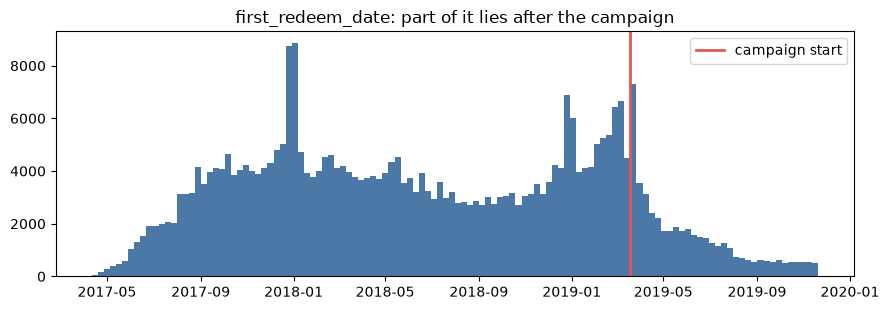

,share,clients
treatment_flg,,
control,0.1110,11110
treatment,0.1149,11490


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.2))
d = clients_raw["first_redeem_date"].dropna()
ax.hist(d, bins=120, color="#4C78A8")
ax.axvline(CAMPAIGN_START, color="#E45756", lw=2, label="campaign start")
ax.set_title("first_redeem_date: part of it lies after the campaign")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "01_redeem_date_leak.png", dpi=150); plt.show()

lab = campaign.merge(clients_raw[["client_id", "first_redeem_date"]], on="client_id")
lab["redeemed_after_campaign"] = lab["first_redeem_date"] >= CAMPAIGN_START
lab.groupby("treatment_flg")["redeemed_after_campaign"].agg(["mean", "sum"]).rename(
    index={0: "control", 1: "treatment"}, columns={"mean": "share", "sum": "clients"})

Treated clients more often have their *first* redemption after the campaign, consistent with the SMS causing it.
A feature built on the raw column partly measures the outcome, which inflates offline scores and fails in production,
because at scoring time that date does not exist yet.

## 4. Was the campaign really randomised?

If treatment and control differ before the campaign, the effect estimate is biased. We compare pre-campaign characteristics
with the **standardised mean difference** (SMD); |SMD| < 0.1 is the usual threshold for "balanced".

In [6]:
activity = con.sql(f'''
    WITH trx AS (
        SELECT client_id, transaction_id, any_value(transaction_datetime) AS ts, any_value(purchase_sum) AS s
        FROM '{purchases}' GROUP BY client_id, transaction_id)
    SELECT client_id, count(*) AS n_transactions, sum(s) AS total_spend,
           date_diff('day', max(ts), TIMESTAMP '{CAMPAIGN_START}') AS days_since_last_purchase
    FROM trx GROUP BY client_id
''').df()

df = (campaign.merge(clients, on="client_id").merge(activity, on="client_id", how="left"))
df["card_age_days"] = (CAMPAIGN_START - df["first_issue_date"]).dt.days
for g in ["F", "M", "U"]:
    df[f"gender_{g}"] = (df["gender"] == g).astype(int)

def smd(x, t):
    a, b = x[t == 1].dropna(), x[t == 0].dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

cols = ["age", "gender_F", "gender_M", "gender_U", "card_age_days", "redeemed_before_campaign",
        "n_transactions", "total_spend", "days_since_last_purchase"]
balance = pd.DataFrame({
    "control_mean": [df.loc[df.treatment_flg == 0, c].astype(float).mean() for c in cols],
    "treatment_mean": [df.loc[df.treatment_flg == 1, c].astype(float).mean() for c in cols],
    "SMD": [smd(df[c].astype(float), df.treatment_flg) for c in cols],
}, index=cols)
share = df.treatment_flg.mean()
p_share = stats.binomtest(int(df.treatment_flg.sum()), len(df), 0.5).pvalue
print(f"treated share: {share:.4f} (binomial test vs 0.5: p = {p_share:.3f})   max |SMD| = {balance.SMD.abs().max():.4f}")
balance

treated share: 0.4998 (binomial test vs 0.5: p = 0.865)   max |SMD| = 0.0085


,control_mean,treatment_mean,SMD
age,46.3781,46.4645,0.0054
gender_F,0.3676,0.3692,0.0032
gender_M,0.1678,0.1673,-0.0013
gender_U,0.4646,0.4635,-0.0021
card_age_days,432.3600,434.1011,0.0085
redeemed_before_campaign,0.7979,0.8007,0.0069
n_transactions,20.0561,20.1856,0.0073
total_spend,"8,569.3661","8,625.6995",0.0063
days_since_last_purchase,6.8294,6.8283,-0.0002


## 5. Average treatment effect (ATE)

In [7]:
def ate_ci(y, t):
    p1, p0 = y[t == 1].mean(), y[t == 0].mean()
    n1, n0 = (t == 1).sum(), (t == 0).sum()
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    return p1 - p0, p1 - p0 - 1.96 * se, p1 - p0 + 1.96 * se, p0, p1

ate, lo, hi, p0, p1 = ate_ci(df.target, df.treatment_flg)
print(f"purchase rate: control {p0:.2%}, treatment {p1:.2%}")
print(f"ATE = {ate*100:+.2f} pp  (95% CI {lo*100:+.2f} … {hi*100:+.2f} pp)")
print(f"relative lift = {ate / p0:+.1%}")

purchase rate: control 60.33%, treatment 63.65%
ATE = +3.32 pp  (95% CI +2.90 … +3.75 pp)
relative lift = +5.5%


The campaign works on average, but the effect is small compared with the base rate: **~60% of clients buy
anyway**. Sending the SMS to everyone pays for 100 messages to get roughly 3 extra buyers.

## 6. Does the effect differ between clients?

Uplift modelling only makes sense if the effect is **heterogeneous**. A first look by simple segments, with 95% confidence
intervals:

days since last purchase: max = 23 → every client bought something in the last 3 weeks; the dataset contains only active clients


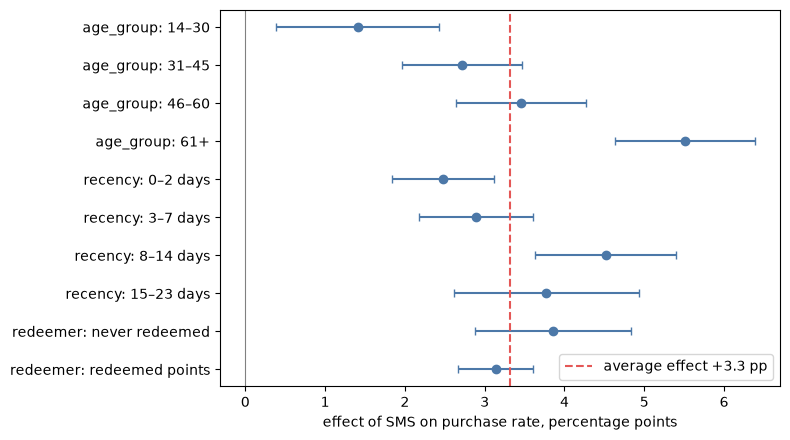

,segment,level,clients,control_rate,effect,ci_low,ci_high
0,age_group,14–30,35535,0.5803,0.0141,0.0038,0.0243
1,age_group,31–45,64857,0.5921,0.0272,0.0197,0.0347
2,age_group,46–60,54016,0.6053,0.0346,0.0264,0.0427
3,age_group,61+,44748,0.6371,0.0551,0.0463,0.0638
4,recency,0–2 days,57451,0.8010,0.0248,0.0184,0.0311
5,recency,3–7 days,67119,0.6488,0.0289,0.0218,0.0360
6,recency,8–14 days,48872,0.4496,0.0452,0.0363,0.0540
7,recency,15–23 days,26597,0.3453,0.0377,0.0262,0.0493
8,redeemer,never redeemed,40146,0.4792,0.0386,0.0288,0.0484
9,redeemer,redeemed points,159893,0.6347,0.0314,0.0267,0.0360


In [8]:
df["age_group"] = pd.cut(df["age"], [13, 30, 45, 60, 100], labels=["14–30", "31–45", "46–60", "61+"])
print("days since last purchase: max =", int(df["days_since_last_purchase"].max()),
      "→ every client bought something in the last 3 weeks; the dataset contains only active clients")
df["recency"] = pd.cut(df["days_since_last_purchase"], [-1, 2, 7, 14, 30],
                       labels=["0–2 days", "3–7 days", "8–14 days", "15–23 days"])
df["redeemer"] = df["redeemed_before_campaign"].map({True: "redeemed points", False: "never redeemed"})

rows = []
for seg in ["age_group", "recency", "redeemer"]:
    for level, g in df.groupby(seg, observed=True):
        a, l, h, p0_, _ = ate_ci(g.target, g.treatment_flg)
        rows.append((seg, str(level), len(g), p0_, a, l, h))
het = pd.DataFrame(rows, columns=["segment", "level", "clients", "control_rate", "effect", "ci_low", "ci_high"])

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(het))[::-1]
ax.errorbar(het.effect * 100, y, xerr=[(het.effect - het.ci_low) * 100, (het.ci_high - het.effect) * 100],
            fmt="o", color="#4C78A8", capsize=3)
ax.axvline(ate * 100, color="#E45756", ls="--", label=f"average effect {ate*100:+.1f} pp")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, het.segment + ": " + het.level)
ax.set_xlabel("effect of SMS on purchase rate, percentage points")
ax.legend(loc="lower right"); fig.tight_layout(); fig.savefig(FIG / "01_effect_by_segment.png", dpi=150); plt.show()
het

## Conclusions for the next steps

* **Leakage:** `first_redeem_date` is censored at the campaign start; all purchase features use only data before 2019-03-19.
* **Data errors:** invalid ages become missing with a flag; basket totals are de-duplicated per transaction.
* **Randomisation holds** (see the SMD table), so the treatment/control difference is a causal effect and offline uplift
  evaluation is valid.
* **The effect is small on average and varies between segments**: it grows with age (≈+1.4 pp for 14–30 vs ≈+5.5 pp
  for 61+, non-overlapping intervals) and is lowest for clients who bought in the last two days. This is exactly the case
  where targeting by uplift beats both "send to everyone" and "send to likely buyers".
* **Limitation:** every client in the data made a purchase in the last 23 days before the campaign, so results describe
  *active* customers; they say nothing about reactivating lapsed ones.
* **Metrics:** accuracy/AUC cannot measure uplift (we never see the same client both treated and untreated). We will use
  uplift@k and the Qini curve, with bootstrap confidence intervals because the effect is small.